# Goolam — i-IF-Learn Replication and Analysis

## 1. Objective

This notebook evaluates i-IF-Learn on the Goolam single-cell RNA-seq dataset, following the methodology described in *i-IF-Learn: Iterative Feature Selection and Unsupervised Learning for High-Dimensional Complex Data*.

The analysis focuses on reproducing the reported clustering accuracy (ACC) and Adjusted Rand Index (ARI) for IF-PCA, i-IF-PCA, and i-IF-Lap. I will also examine how iterative refinement changes the selected features and predicted cluster labels, and whether these changes improve clustering performance.

The results will be compared with the original paper, followed by an analysis of feature-selection stability and computational cost.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from pathlib import Path

from Src.data_loader import load_dataset
from Src.ifpca import run_ifpca
from Src.iiflearn import run_i_if_learn
from Src.evaluation import evaluate_clustering

print("All imports successful!")


All imports successful!


## 2. Dataset Loading and Understanding

The Goolam dataset is a single-cell RNA-seq dataset containing gene expression measurements. Each row represents a sample, while each column represents a gene.

I will first examine the dataset dimensions, number of clusters, and distribution of samples across the reference classes. These labels will be used only for evaluation, not for feature selection or clustering.

In [2]:

X, y, K = load_dataset(
    "goolam",
    scrna_dir="./8 Single-Cell RNA-seq Datasets/8 Single-Cell RNA-seq Datasets"
)

print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of clusters (K):", K)

print("\nClass distribution:")
classes, counts = np.unique(y, return_counts=True)

for label, count in zip(classes, counts):
    print(f"Class {label}: {count} samples")


Dataset shape: (124, 21199)
Number of samples: 124
Number of features: 21199
Number of clusters (K): 5

Class distribution:
Class 0: 6 samples
Class 1: 16 samples
Class 2: 64 samples
Class 3: 32 samples
Class 4: 6 samples


### Dataset Observations

The Goolam dataset contains 124 samples and 21,199 gene expression features, with five reference classes. The number of features is substantially larger than the number of samples, making this a high-dimensional clustering problem.

The class distribution is imbalanced, with the largest class containing 64 samples and the two smallest classes containing only six samples each. This may make it challenging to distinguish smaller clusters.

Both ACC and ARI will be used to evaluate clustering performance. Reference labels will only be used for evaluation and analysis, not for training or feature selection.

In [3]:

# Basic data quality checks

print("Missing values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())
print("Zero values (%):", round(np.mean(X == 0) * 100, 2))

feature_std = np.std(X, axis=0)
print("Constant features:", np.sum(feature_std == 0))

print("Minimum expression value:", np.min(X))
print("Maximum expression value:", np.max(X))


Missing values: 0
Infinite values: 0
Zero values (%): 39.16
Constant features: 0
Minimum expression value: 0.0
Maximum expression value: 2.9661865662267077


### Data Quality Observations

The Goolam dataset contains no missing or infinite values, and none of its 21,199 features have zero variance.

Approximately 39.16% of the gene expression measurements are zero, indicating substantial sparsity. This is common in single-cell RNA-seq data and may reflect both biological expression patterns and technical limitations.

For the primary replication, I will retain the dataset in its loaded form and follow the preprocessing performed by the clustering implementation rather than introducing additional transformations.

In [4]:

# IF-PCA baseline on Goolam

start_time = time.perf_counter()

ifpca_result = run_ifpca(
    X,
    K,
    threshold=None,
    null_rep=100000,
    random_state=42
)

ifpca_runtime = time.perf_counter() - start_time

# Unpack results
initial_labels, selected_features, pca_embedding, ks_scores, ks_pvalues = ifpca_result

# Evaluate clustering
ifpca_metrics = evaluate_clustering(y, initial_labels)

print("IF-PCA ACC:", round(ifpca_metrics["Accuracy"], 4))
print("IF-PCA ARI:", round(ifpca_metrics["ARI"], 4))
print("Selected features:", len(selected_features))
print("PCA embedding shape:", pca_embedding.shape)
print("Runtime (s):", round(ifpca_runtime, 4))


IF-PCA ACC: 0.5887
IF-PCA ARI: 0.2687
Selected features: 6021
PCA embedding shape: (124, 4)
Runtime (s): 37.3262


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### IF-PCA Results and Interpretation

IF-PCA achieved an accuracy (ACC) of 0.5887 and an Adjusted Rand Index (ARI) of 0.2687 on the Goolam dataset. These results are lower than the paper's reported ACC of 0.721 and ARI of 0.537.

The method selected 6,021 out of 21,199 genes (28.4%) and produced a four-dimensional PCA embedding. The execution time was approximately 37.33 seconds.

The difference from the published results may be related to preprocessing, random initialization, or implementation details. Further experiments are needed to determine the cause.

In [6]:

import json
import time
import pandas as pd
from pathlib import Path

seeds = range(10)

results_path = Path("goolam_ifpca_10_seeds.csv")
features_path = Path("goolam_ifpca_feature_sets.json")

# Load any previously saved runs so interrupted experiments can resume.
if results_path.exists():
    stability_results = pd.read_csv(results_path).to_dict("records")
else:
    stability_results = []

if features_path.exists():
    with open(features_path, "r") as f:
        feature_sets = json.load(f)
else:
    feature_sets = {}

completed_seeds = {
    int(row["Seed"]) for row in stability_results
    if str(int(row["Seed"])) in feature_sets
}

for seed in seeds:
    if seed in completed_seeds:
        print(f"Seed {seed} already saved. Skipping.")
        continue

    start = time.perf_counter()

    output = run_ifpca(
        X,
        K,
        threshold=None,
        null_rep=100000,
        random_state=seed
    )

    elapsed = time.perf_counter() - start

    labels, features, embedding, ks_scores, ks_pvalues = output
    metrics = evaluate_clustering(y, labels)

    # Save selected gene indices
    feature_sets[str(seed)] = [
        int(index) for index in features
    ]

    # Save performance results
    stability_results = [
        row for row in stability_results
        if int(row["Seed"]) != seed
    ]

    stability_results.append({
        "Seed": seed,
        "ACC": metrics["Accuracy"],
        "ARI": metrics["ARI"],
        "Selected Features": len(features),
        "Runtime (s)": elapsed
    })

    pd.DataFrame(stability_results).sort_values(
        "Seed"
    ).to_csv(results_path, index=False)

    with open(features_path, "w") as f:
        json.dump(feature_sets, f)

    print(
        f"Seed {seed}: "
        f"ACC={metrics['Accuracy']:.4f}, "
        f"ARI={metrics['ARI']:.4f}, "
        f"Features={len(features)}, "
        f"Runtime={elapsed:.2f}s"
    )

ifpca_stability_df = pd.DataFrame(
    stability_results
).sort_values("Seed")

display(ifpca_stability_df)


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Seed 0: ACC=0.6076, ARI=0.3636, Features=5493, Runtime=23.57s


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Seed 1: ACC=0.5736, ARI=0.3124, Features=5581, Runtime=23.29s


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Seed 2: ACC=0.5763, ARI=0.3167, Features=5508, Runtime=25.40s


... (10 outputs left out)

C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Seed 8: ACC=0.5763, ARI=0.3167, Features=5508, Runtime=23.23s
Seed 9: ACC=0.6049, ARI=0.3562, Features=5157, Runtime=23.80s


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,Seed,ACC,ARI,Selected Features,Runtime (s)
0,0,0.607629,0.363649,5493,23.573248
1,1,0.573569,0.312446,5581,23.291900
2,2,0.576294,0.316670,5508,25.399666
3,3,0.573569,0.312446,5581,25.256111
4,4,0.576294,0.316261,5613,23.114096
5,5,0.576294,0.316261,5613,23.479840
6,6,0.610354,0.362072,5150,24.568454
7,7,0.576294,0.316261,5613,23.288210
8,8,0.576294,0.316670,5508,23.226137
9,9,0.604905,0.356208,5157,23.804347


### IF-PCA Random Seed Stability Analysis

I evaluated IF-PCA on Goolam using 10 random seeds (0–9) to examine the stability of clustering performance and feature selection.

The mean ACC was 0.5851 ± 0.0156, and the mean ARI was 0.3289 ± 0.0220. The number of selected genes ranged from 5,150 to 5,613, with an average of approximately 5,482.

The results show moderate variation across random seeds, but all 10 runs produced lower ACC and ARI than the paper's reported values of 0.721 and 0.537. This suggests that random seed variation within the tested range does not fully explain the replication discrepancy.

The selected gene counts also vary across runs. I will use Jaccard similarity to examine whether the actual selected gene sets overlap consistently.

In [7]:

import json
from itertools import combinations

with open("goolam_ifpca_feature_sets.json", "r") as f:
    feature_sets = json.load(f)

jaccard_scores = []

for seed_a, seed_b in combinations(range(10), 2):
    A = set(feature_sets[str(seed_a)])
    B = set(feature_sets[str(seed_b)])

    jaccard = len(A & B) / len(A | B)
    jaccard_scores.append(jaccard)

print("Number of seed pairs:", len(jaccard_scores))
print("Mean Jaccard:", round(np.mean(jaccard_scores), 4))
print("Std Jaccard:", round(np.std(jaccard_scores, ddof=1), 4))
print("Minimum Jaccard:", round(np.min(jaccard_scores), 4))
print("Maximum Jaccard:", round(np.max(jaccard_scores), 4))


Number of seed pairs: 45
Mean Jaccard: 0.9671
Std Jaccard: 0.0317
Minimum Jaccard: 0.9175
Maximum Jaccard: 1.0


### IF-PCA Feature Selection Stability

I evaluated the stability of IF-PCA's selected genes across 10 random seeds using pairwise Jaccard similarity.

Across the 45 seed pairs, the mean Jaccard similarity was 0.9671, with a standard deviation of 0.0317. The similarities ranged from 0.9175 to 1.0000, indicating that IF-PCA consistently selected highly overlapping gene sets.

Despite this high feature-selection stability, clustering performance varied across seeds, and all runs produced lower ACC and ARI than the paper's reported values.

This suggests that stable feature selection alone does not guarantee high clustering accuracy. Further analysis is needed to understand whether changes in clustering assignments, selected features, or implementation details contribute to these differences.

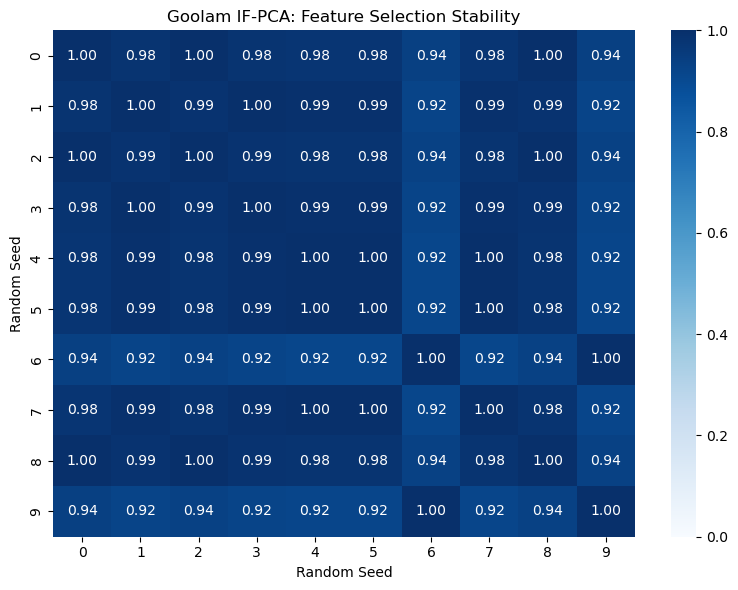

In [8]:
# Pairwise Jaccard similarity matrix

jaccard_matrix = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        A = set(feature_sets[str(i)])
        B = set(feature_sets[str(j)])

        jaccard_matrix[i, j] = len(A & B) / len(A | B)

plt.figure(figsize=(8, 6))

sns.heatmap(
    jaccard_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Goolam IF-PCA: Feature Selection Stability")
plt.xlabel("Random Seed")
plt.ylabel("Random Seed")

plt.tight_layout()
plt.show()


### Jaccard Similarity Heatmap

The Jaccard similarity heatmap shows substantial overlap between the gene sets selected by IF-PCA across 10 random seeds. Most pairwise similarities are close to 1.0, with an overall mean of 0.9671.

Seeds 6 and 9 form a distinct group, showing slightly lower overlap with the other seeds. These runs also achieved relatively higher clustering accuracy.

Despite selecting highly similar gene sets, IF-PCA did not reproduce the paper's reported ACC and ARI on Goolam. This suggests that high feature-selection stability does not necessarily guarantee high clustering performance. The source of the replication discrepancy requires further investigation.

In [9]:
# i-IF-PCA replication on Goolam

start_time = time.perf_counter()

iifpca_result = run_i_if_learn(
    X,
    K,
    method="PCA",
    seed=42,
    max_iter=10,
    convergence_threshold=0.1,
    random_trials=200,
    ks_repetitions=100000
)

iifpca_runtime = time.perf_counter() - start_time

iifpca_metrics = evaluate_clustering(
    y, iifpca_result["labels"]
)

print("i-IF-PCA ACC:", round(iifpca_metrics["Accuracy"], 4))
print("i-IF-PCA ARI:", round(iifpca_metrics["ARI"], 4))
print("Selected features:", len(iifpca_result["features"]))
print("Iterations:", len(iifpca_result["history"]))
print("Runtime (s):", round(iifpca_runtime, 4))


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with M

Iteration 1: features=843, w=1.0000, change=0.1051


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


Iteration 2: features=1060, w=1.0000, change=0.3642
Iteration 3: features=1092, w=1.0000, change=0.0745
Converged after 3 iterations.
i-IF-PCA ACC: 0.7003
i-IF-PCA ARI: 0.5336
Selected features: 1092
Iterations: 3
Runtime (s): 1443.9583


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [10]:

import numpy as np
import inspect
from Src.iiflearn import run_i_if_learn

print("Loaded implementation:")
print(inspect.getfile(run_i_if_learn))

print("\nInitial feature count:")
print(len(iifpca_result["initial_features"]))

print("\nStandalone IF-PCA feature count:")
print(len(selected_features))

print("\nSame initial selected genes?")
print(
    np.array_equal(
        np.sort(iifpca_result["initial_features"]),
        np.sort(selected_features)
    )
)

print("\nSame initial cluster labels?")
print(
    np.array_equal(
        iifpca_result["initial_labels"],
        initial_labels
    )
)


Loaded implementation:
C:\Users\priyam\Desktop\Semester2\Machine_Learning\Decison_Tree\Project\Clustering\Src\iiflearn.py

Initial feature count:
5507

Standalone IF-PCA feature count:
6021

Same initial selected genes?
False

Same initial cluster labels?
False


In [11]:

# Recheck IF-PCA initialization with seed 42

check_result = run_ifpca(
    X,
    K,
    threshold=None,
    null_rep=100000,
    random_state=42
)

check_labels, check_features, _, _, _ = check_result

print("Original standalone features:", len(selected_features))
print("Fresh standalone features:", len(check_features))
print("i-IF-PCA initial features:", len(iifpca_result["initial_features"]))

print(
    "Fresh matches original:",
    np.array_equal(
        np.sort(check_features),
        np.sort(selected_features)
    )
)

print(
    "Fresh matches i-IF-PCA:",
    np.array_equal(
        np.sort(check_features),
        np.sort(iifpca_result["initial_features"])
    )
)

print(
    "Fresh labels match i-IF-PCA:",
    np.array_equal(
        check_labels,
        iifpca_result["initial_labels"]
    )
)


Original standalone features: 6021
Fresh standalone features: 5507
i-IF-PCA initial features: 5507
Fresh matches original: False
Fresh matches i-IF-PCA: True
Fresh labels match i-IF-PCA: True


C:\Users\priyam\Python\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [12]:

import numpy as np
import pandas as pd
from Src.data_loader import load_dataset

microarray_dir = "./10 Gene Microarray Datasets/10 Gene Microarray Datasets"
scrna_dir = "./8 Single-Cell RNA-seq Datasets/8 Single-Cell RNA-seq Datasets"

datasets = {
    "SRBCT": ("srbct", "microarray"),
    "Leukemia": ("leukemia", "microarray"),
    "Colon Cancer": ("colon", "microarray"),
    "Deng": ("deng", "scrna"),
    "Goolam": ("goolam", "scrna"),
    "Camp2": ("camp2", "scrna")
}

rows = []

for display_name, (name, data_type) in datasets.items():
    kwargs = (
        {"microarray_dir": microarray_dir}
        if data_type == "microarray"
        else {"scrna_dir": scrna_dir}
    )

    X, y, K = load_dataset(name, **kwargs)

    rows.append({
        "Dataset": display_name,
        "Samples": X.shape[0],
        "Features": X.shape[1],
        "Classes (K)": K,
        "Labels": len(y),
        "Missing values": int(np.isnan(X).sum())
    })

dataset_summary = pd.DataFrame(rows)
display(dataset_summary)


,Dataset,Samples,Features,Classes (K),Labels,Missing values
0,SRBCT,63,2308,4,63,0
1,Leukemia,72,3571,2,72,0
2,Colon Cancer,62,2000,2,62,0
3,Deng,268,16347,6,268,0
4,Goolam,124,21199,5,124,0
5,Camp2,734,11233,6,734,0
